In [1]:
import pandas as pd
from torchvision import datasets

dataset = datasets.FashionMNIST(
    root = "./data",
    train = True,
    download = True,
)

labels = dataset.targets

print(labels.shape)
print(labels[:10])

label_series = pd.Series(labels.numpy())
print(label_series.head())

class_counts = label_series.value_counts().sort_index()
print(class_counts)







torch.Size([60000])
tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5])
0    9
1    0
2    0
3    3
4    0
dtype: int64
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [2]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print(class_names[0])
print(class_names[9])

T-shirt/top
Ankle boot


In [3]:
df_counts = pd.DataFrame({
    "label": range(10),
    "class_name": class_names,
    "count":class_counts.values
})

print(df_counts)



   label   class_name  count
0      0  T-shirt/top   6000
1      1      Trouser   6000
2      2     Pullover   6000
3      3        Dress   6000
4      4         Coat   6000
5      5       Sandal   6000
6      6        Shirt   6000
7      7      Sneaker   6000
8      8          Bag   6000
9      9   Ankle boot   6000


In [4]:
print(df_counts.shape)
print(df_counts.columns)

print(df_counts.head(3))


(10, 3)
Index(['label', 'class_name', 'count'], dtype='str')
   label   class_name  count
0      0  T-shirt/top   6000
1      1      Trouser   6000
2      2     Pullover   6000


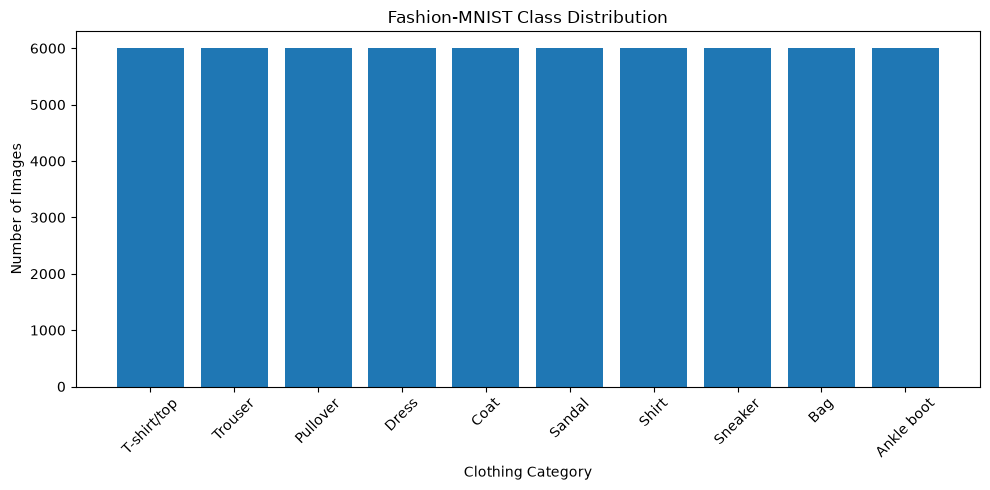

In [5]:
import matplotlib.pyplot as plt

#1.绘制画布
plt.figure(figsize=(10,5))

#2.绘制柱状图
plt.bar(
    df_counts["class_name"],
    df_counts["count"]
)

#3.添加标题和标签
plt.title("Fashion-MNIST Class Distribution")
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")

#4.调整横轴标签
plt.xticks(rotation=45)

#5.自动调整布局
plt.tight_layout()

#6.显示图表
plt.show()






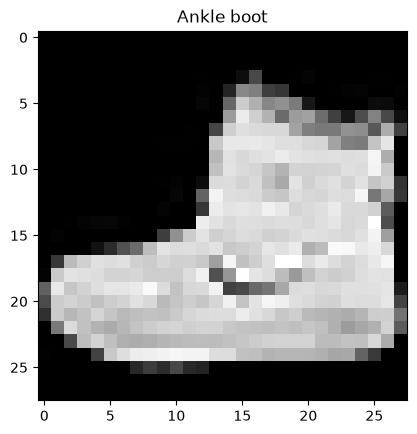

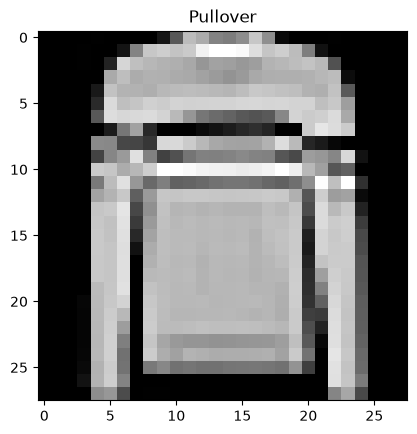

In [6]:
import matplotlib.pyplot as plt

#获取第一章图片和标签
image,label = dataset[0]

#显示图片
plt.imshow(image,cmap = "gray")
plt.title(class_names[label])
plt.show()

image,label = dataset[5]

plt.imshow(image,cmap = "gray")
plt.title(class_names[label])
plt.show()



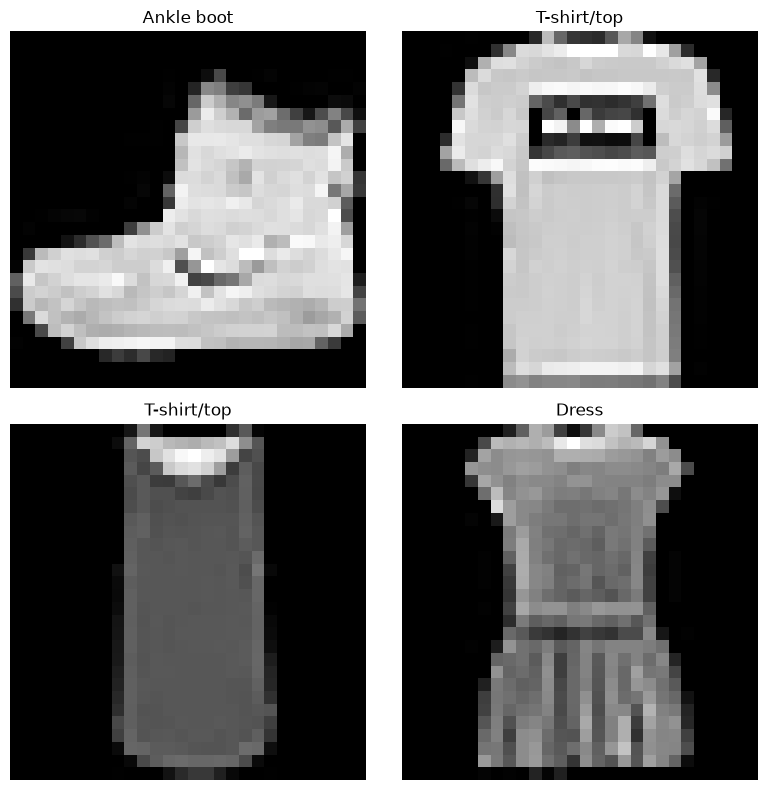

In [7]:
import matplotlib.pyplot as plt

#创建一个8x8英寸的画布
plt.figure(figsize=(8,8))

#循环显示四张图片
for i in range(4):

    #获取图片和标签
    image,label = dataset[i]
    
    #选择绘图位置
    plt.subplot(2,2,i+1)

    #显示图片
    plt.imshow(image,cmap = "gray")

    #显示类别名称
    plt.title(class_names[label])

    #隐藏坐标轴
    plt.axis("off")
    
plt.tight_layout()
plt.show()


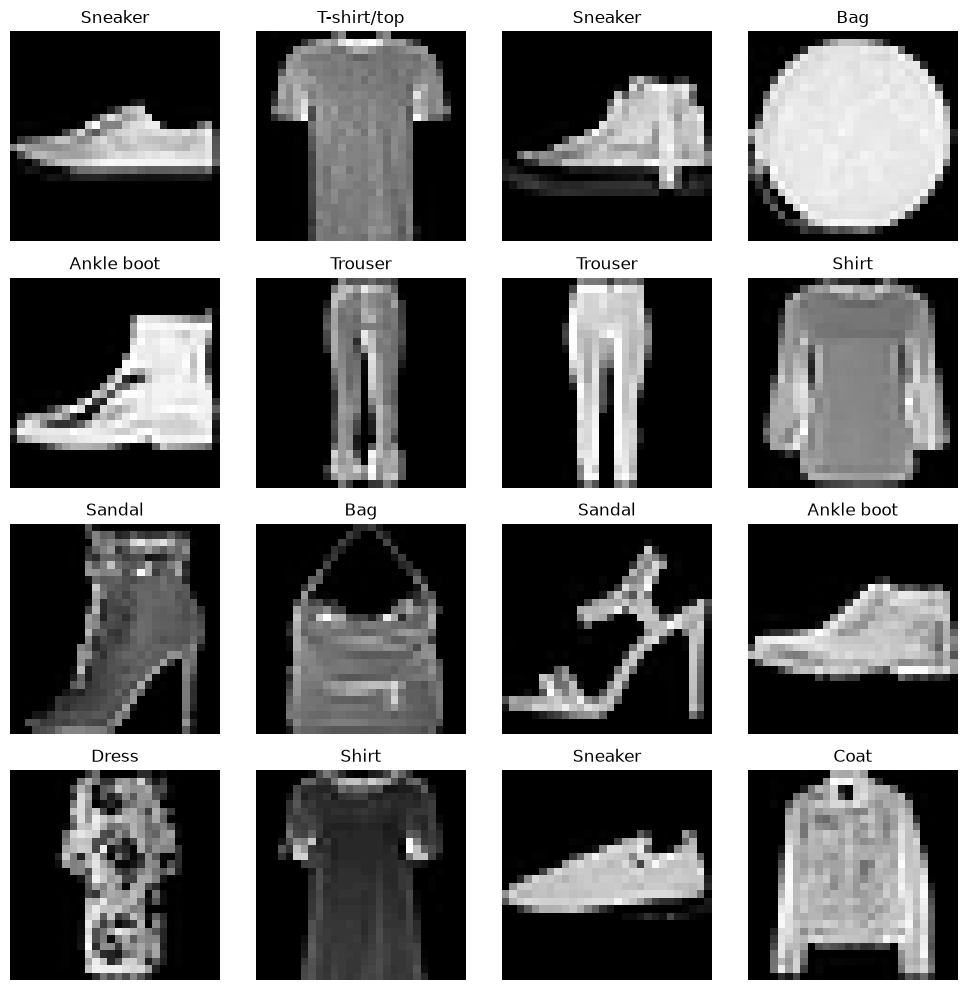

In [8]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

random_indices = rng.choice(
    len(dataset),
    size = 16,
    replace = False
)

plt.figure(figsize = (10,10))

#修改循环，让它执行16次
for i in range(16):
    
    #根据random_indices获取图片和标签
    image,label = dataset[random_indices[i]]
    
    #将子图布局设置为4行4列，每个子图显示一张图片
    plt.subplot(4,4,i + 1)

    plt.imshow(image,cmap = "gray")
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()




In [9]:
#Fashion—MNIST原始训练图片

images = dataset.data

print("图片数据形状:",images.shape)
print("数据类型:",images.dtype)

images_np = images.numpy()

print(type(images_np))
print(images_np.shape)

images_np = images_np.astype(np.float32) / 255.0

pixel_mean = images_np.mean()
pixel_std = images_np.std()

print("整个训练集像素平均值:",pixel_mean)
print("整个训练集像素标准差:",pixel_std)

图片数据形状: torch.Size([60000, 28, 28])
数据类型: torch.uint8
<class 'numpy.ndarray'>
(60000, 28, 28)
整个训练集像素平均值: 0.2860406
整个训练集像素标准差: 0.35302424
